In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


Upload Dataset

In [3]:
from google.colab import files

uploaded = files.upload()

Saving KT_GameBox_1.csv to KT_GameBox_1 (1).csv


Successfully Upload

In [4]:
df = pd.read_csv("KT_GameBox_1.csv")

print("Dataset Loaded Successfully!")

df.head()

Dataset Loaded Successfully!


,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-10-05 14:28:49.564595,192.0.0.2,10.215.173.2,TCP,60,47254 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...
1,2,2022-10-05 14:28:51.317163,10.215.173.1,10.215.173.2,DNS,68,Standard query 0xa610 A gbc.play.ktgamebox.com
2,3,2022-10-05 14:28:51.348247,10.215.173.2,10.215.173.1,DNS,168,Standard query response 0xa610 A gbc.play.ktga...
3,4,2022-10-05 14:28:51.351537,10.215.173.1,211.252.120.14,TCP,60,60014 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...
4,5,2022-10-05 14:28:51.372722,211.252.120.14,10.215.173.1,TCP,48,"443 > 60014 [SYN, ACK] Seq=0 Ack=1 Win=2048 ..."


Understand Dataset

In [5]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Information:")
display(df.describe())

print("\nFirst 10 Rows:")
display(df.head(10))

Dataset Shape:
(1512728, 7)

Column Names:
Index(['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1512728 entries, 0 to 1512727
Data columns (total 7 columns):
 #   Column       Non-Null Count    Dtype 
---  ------       --------------    ----- 
 0   No.          1512728 non-null  int64 
 1   Time         1512728 non-null  object
 2   Source       1512728 non-null  object
 3   Destination  1512728 non-null  object
 4   Protocol     1512728 non-null  object
 5   Length       1512728 non-null  int64 
 6   Info         1512728 non-null  object
dtypes: int64(2), object(5)
memory usage: 80.8+ MB

Statistical Information:


,No.,Length
count,1.512728e+06,1.512728e+06
mean,7.563645e+05,1.285918e+03
std,4.366871e+05,1.021589e+03
min,1.000000e+00,3.200000e+01
25%,3.781828e+05,1.300000e+03
50%,7.563645e+05,1.300000e+03
75%,1.134546e+06,1.300000e+03
max,1.512728e+06,1.000000e+04



First 10 Rows:


,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-10-05 14:28:49.564595,192.0.0.2,10.215.173.2,TCP,60,47254 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...
1,2,2022-10-05 14:28:51.317163,10.215.173.1,10.215.173.2,DNS,68,Standard query 0xa610 A gbc.play.ktgamebox.com
2,3,2022-10-05 14:28:51.348247,10.215.173.2,10.215.173.1,DNS,168,Standard query response 0xa610 A gbc.play.ktga...
3,4,2022-10-05 14:28:51.351537,10.215.173.1,211.252.120.14,TCP,60,60014 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...
4,5,2022-10-05 14:28:51.372722,211.252.120.14,10.215.173.1,TCP,48,"443 > 60014 [SYN, ACK] Seq=0 Ack=1 Win=2048 ..."
5,6,2022-10-05 14:28:51.372868,10.215.173.1,211.252.120.14,TCP,40,60014 > 443 [ACK] Seq=1 Ack=1 Win=79872 Len=0
6,7,2022-10-05 14:28:51.382909,10.215.173.1,211.252.120.14,TLSv1.3,557,Client Hello
7,8,2022-10-05 14:28:51.383112,211.252.120.14,10.215.173.1,TCP,40,443 > 60014 [ACK] Seq=1 Ack=518 Win=2096128 ...
8,9,2022-10-05 14:28:51.398323,10.215.173.1,10.215.173.2,DNS,68,Standard query 0x30a1 A gba.play.ktgamebox.com
9,10,2022-10-05 14:28:51.413707,211.252.120.14,10.215.173.1,TLSv1.3,4136,"Server Hello, Change Cipher Spec, Application ..."


Use 100,000 Rows

In [6]:
df = df.head(100000).copy()

print("Dataset Shape:", df.shape)

Dataset Shape: (100000, 7)


Check Missing Values

In [7]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
No.            0
Time           0
Source         0
Destination    0
Protocol       0
Length         0
Info           0
dtype: int64


Remove Duplicate Records

In [8]:
print("Duplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:")
print(df.shape)

Duplicate Records: 0
Dataset Shape After Removing Duplicates:
(100000, 7)


Check Protocol Types

In [9]:
print("Available Protocols:")

print(df["Protocol"].unique())

Available Protocols:
['TCP' 'DNS' 'TLSv1.3' 'TLSv1' 'UDP' 'TLSv1.2']


Count Each Protocol

In [10]:
print(df["Protocol"].value_counts())

Protocol
UDP        85944
TCP        13876
TLSv1        115
TLSv1.3       42
TLSv1.2       13
DNS           10
Name: count, dtype: int64


Visualize Protocol Distribution

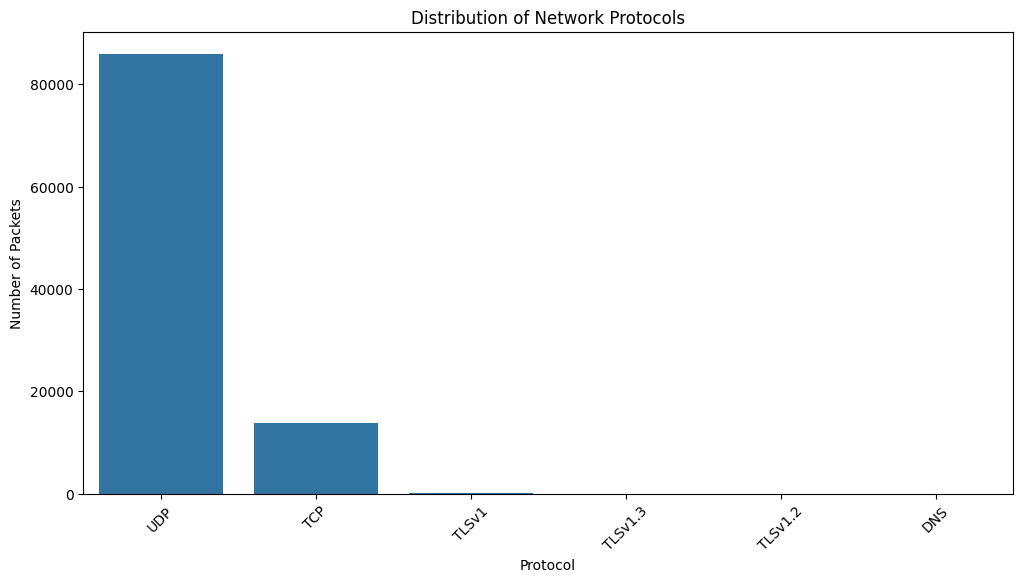

In [11]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index
)

plt.xticks(rotation=45)
plt.title("Distribution of Network Protocols")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")

plt.show()

Analyze Packet Length

In [12]:
df["Length"] = pd.to_numeric(
    df["Length"],
    errors="coerce"
)

print(df["Length"].describe())

count    100000.000000
mean       1261.800620
std         976.958884
min          32.000000
25%        1300.000000
50%        1300.000000
75%        1300.000000
max       10000.000000
Name: Length, dtype: float64


Histogram

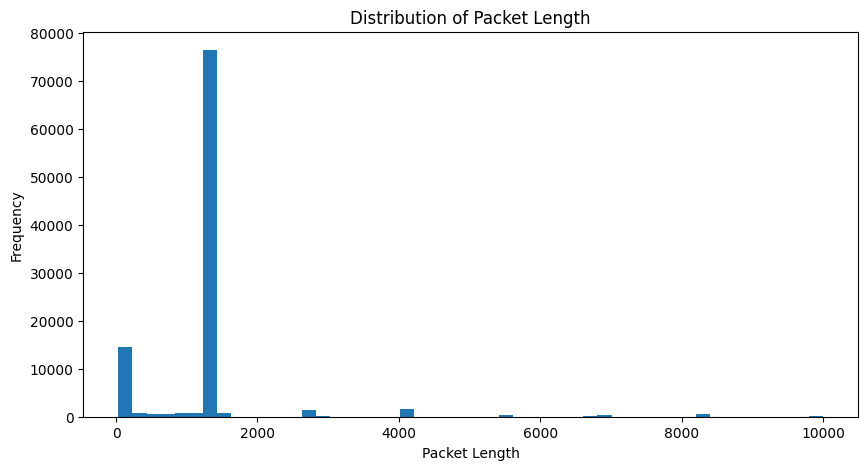

In [13]:
plt.figure(figsize=(10, 5))

plt.hist(df["Length"].dropna(), bins=50)

plt.title("Distribution of Packet Length")
plt.xlabel("Packet Length")
plt.ylabel("Frequency")

plt.show()

Box plot

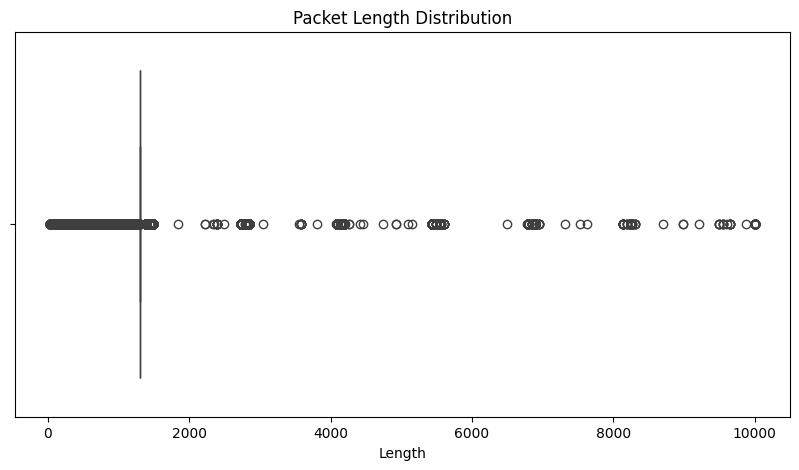

In [14]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Length"])

plt.title("Packet Length Distribution")

plt.show()

Feature Engineering

Convert Time into datetime

In [15]:
df["Time"] = pd.to_datetime(
    df["Time"],
    errors="coerce"
)

Extract Hour, Minute and Second

In [16]:
df["Hour"] = df["Time"].dt.hour

df["Minute"] = df["Time"].dt.minute

df["Second"] = df["Time"].dt.second

Check

In [17]:
display(
    df[["Time", "Hour", "Minute", "Second"]].head()
)

,Time,Hour,Minute,Second
0,2022-10-05 14:28:49.564595,14,28,49
1,2022-10-05 14:28:51.317163,14,28,51
2,2022-10-05 14:28:51.348247,14,28,51
3,2022-10-05 14:28:51.351537,14,28,51
4,2022-10-05 14:28:51.372722,14,28,51


Select Features

Our input features will be:
- Length
- Hour
- Minute
- Second
target variable will be:

- Protocol

In [18]:
X = df[[
    "Length",
    "Hour",
    "Minute",
    "Second"
]]

y = df["Protocol"]

Check

In [19]:
print("Input Features:")
display(X.head())

print("Target Variable:")
display(y.head())

print("X Shape:", X.shape)
print("Y Shape:", y.shape)

Input Features:


,Length,Hour,Minute,Second
0,60,14,28,49
1,68,14,28,51
2,168,14,28,51
3,60,14,28,51
4,48,14,28,51


Target Variable:


,Protocol
0,TCP
1,DNS
2,DNS
3,TCP
4,TCP


X Shape: (100000, 4)
Y Shape: (100000,)


Handle Missing Values

In [20]:
X = X.fillna(0)

print("Missing Values After Cleaning:")
print(X.isnull().sum())

Missing Values After Cleaning:
Length    0
Hour      0
Minute    0
Second    0
dtype: int64


Encode Protocol

In [21]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Protocol Classes:")
print(label_encoder.classes_)

print("\nEncoded Values:")
print(y_encoded[:20])

Protocol Classes:
['DNS' 'TCP' 'TLSv1' 'TLSv1.2' 'TLSv1.3' 'UDP']

Encoded Values:
[1 0 0 1 1 1 4 1 0 4 1 4 1 4 1 4 1 0 1 4]


Train-Test Split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training Samples:", X_train.shape[0])

print("Testing Samples:", X_test.shape[0])

Training Samples: 80000
Testing Samples: 20000


Feature Scaling

In [23]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


Logistic Regression

In [24]:
logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred_lr = logistic_model.predict(X_test_scaled)

accuracy_lr = accuracy_score(
    y_test,
    y_pred_lr
)

print("Logistic Regression Accuracy:",
      accuracy_lr * 100, "%")

Logistic Regression Accuracy: 87.775 %


K-Nearest Neighbors (KNN)

In [25]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

y_pred_knn = knn_model.predict(X_test_scaled)

accuracy_knn = accuracy_score(
    y_test,
    y_pred_knn
)

print("KNN Accuracy:",
      accuracy_knn * 100, "%")

KNN Accuracy: 99.63 %


Decision Tree

In [26]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt_model.fit(
    X_train,
    y_train
)

y_pred_dt = dt_model.predict(X_test)

accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print("Decision Tree Accuracy:",
      accuracy_dt * 100, "%")

Decision Tree Accuracy: 99.83999999999999 %


Visualize Decision Tree

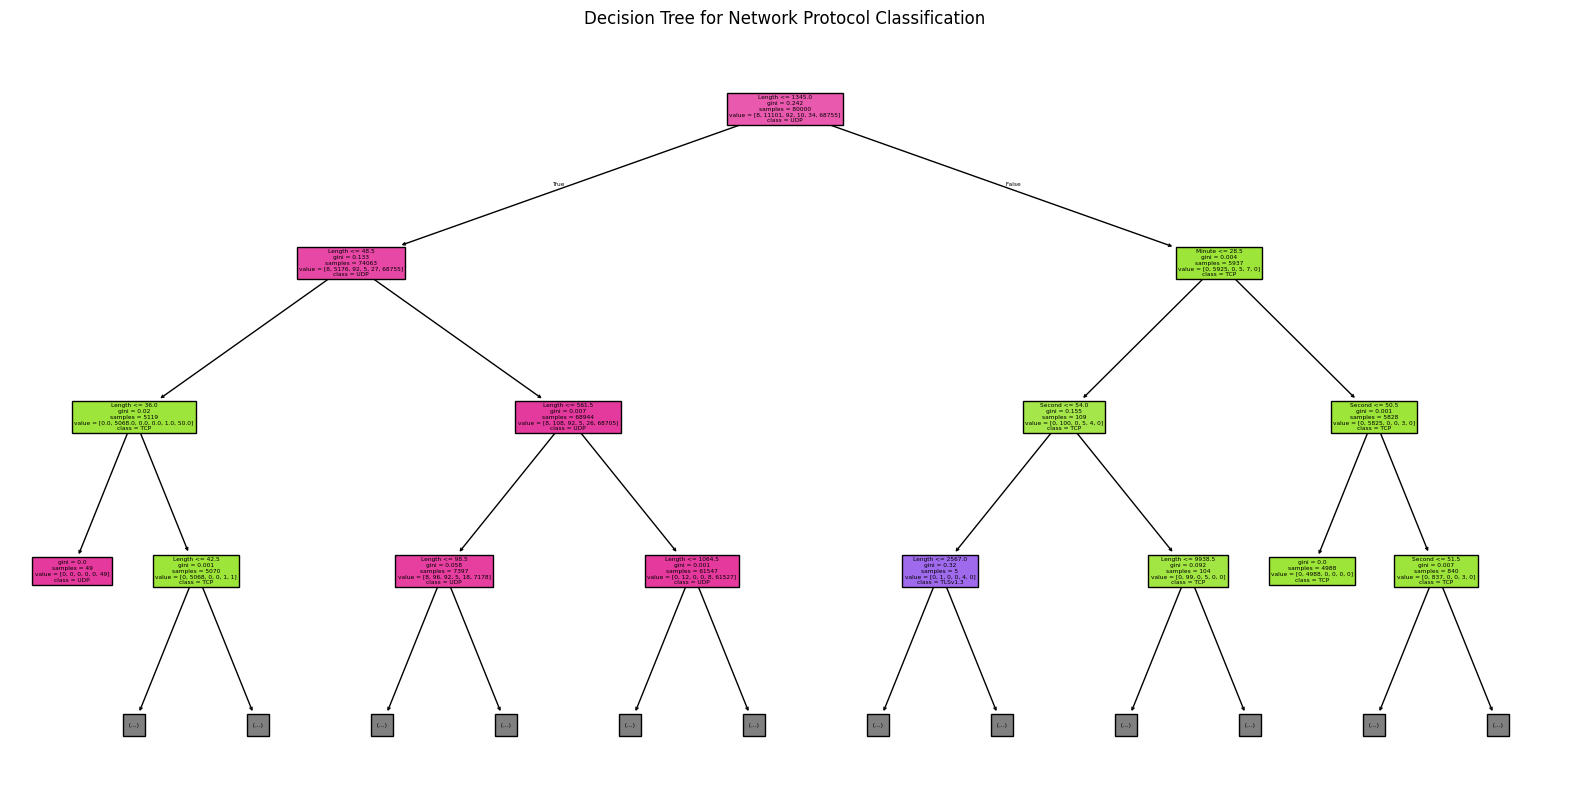

In [27]:
plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    max_depth=3
)

plt.title("Decision Tree for Network Protocol Classification")

plt.show()

Random Forest

In [28]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

y_pred_rf = rf_model.predict(X_test)

accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print("Random Forest Accuracy:",
      accuracy_rf * 100, "%")

Random Forest Accuracy: 99.79 %


Compare All Models

In [29]:
results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_lr,
        accuracy_knn,
        accuracy_dt,
        accuracy_rf
    ]

})

results["Accuracy (%)"] = results["Accuracy"] * 100

display(results)

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.87775,87.775
1,KNN,0.99630,99.630
2,Decision Tree,0.99840,99.840
3,Random Forest,0.99790,99.790


Model Comparison Graph

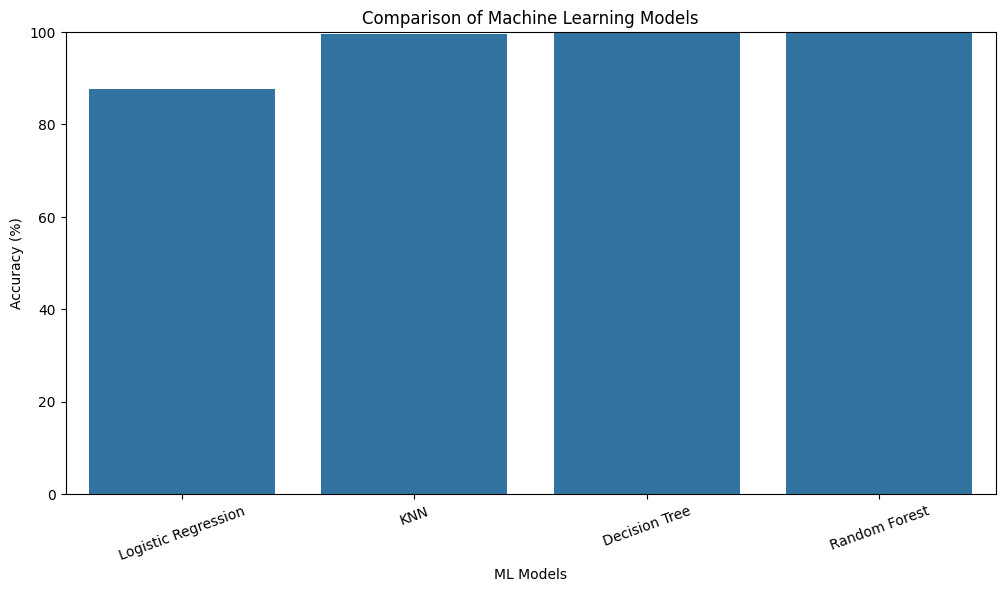

In [30]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.xticks(rotation=20)

plt.ylim(0, 100)

plt.title("Comparison of Machine Learning Models")

plt.xlabel("ML Models")

plt.ylabel("Accuracy (%)")

plt.show()

Find Best Model

In [31]:
best_model = results.loc[
    results["Accuracy"].idxmax()
]

print("Best Machine Learning Model:")

print(best_model)

Best Machine Learning Model:
Model           Decision Tree
Accuracy               0.9984
Accuracy (%)            99.84
Name: 2, dtype: object


Feature Importance

In [32]:
feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": rf_model.feature_importances_

})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
0,Length,0.985337
2,Minute,0.009183
3,Second,0.005480
1,Hour,0.000000


Graph

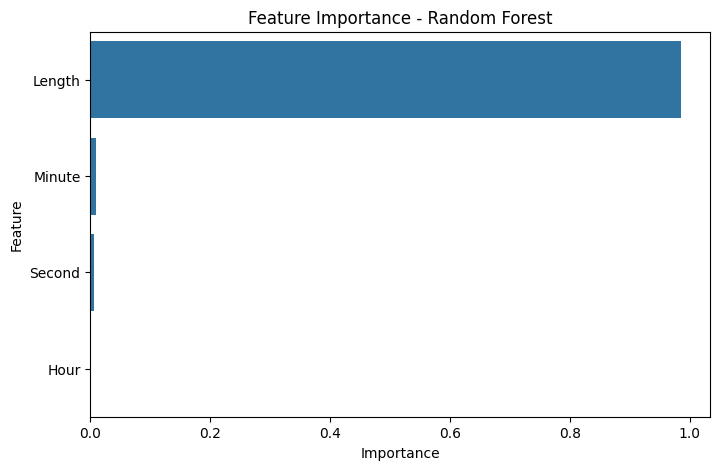

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")

plt.show()

Classification Report

In [34]:
print("Random Forest Classification Report:")

print(
    classification_report(
        y_test,
        y_pred_rf,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Random Forest Classification Report:
              precision    recall  f1-score   support

         DNS       0.50      0.50      0.50         2
         TCP       1.00      1.00      1.00      2775
       TLSv1       0.58      0.48      0.52        23
     TLSv1.2       0.00      0.00      0.00         3
     TLSv1.3       1.00      0.50      0.67         8
         UDP       1.00      1.00      1.00     17189

    accuracy                           1.00     20000
   macro avg       0.68      0.58      0.61     20000
weighted avg       1.00      1.00      1.00     20000



Confusion Matrix

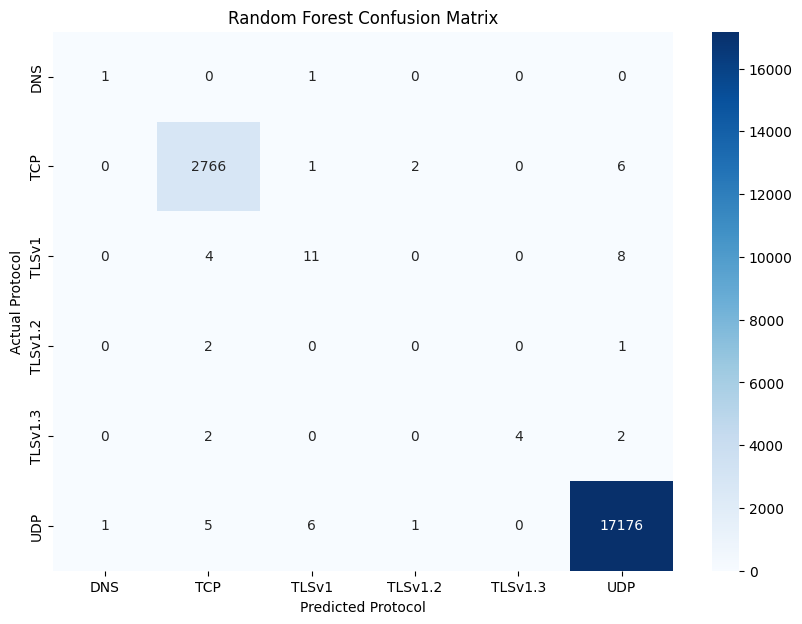

In [35]:
cm = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Protocol")

plt.ylabel("Actual Protocol")

plt.title("Random Forest Confusion Matrix")

plt.show()

Predict a New Network Packet

In [36]:
new_packet = pd.DataFrame({

    "Length": [64],

    "Hour": [10],

    "Minute": [30],

    "Second": [15]

})

prediction = rf_model.predict(new_packet)

predicted_protocol = label_encoder.inverse_transform(
    prediction
)

print("New Packet Details:")

display(new_packet)

print("Predicted Protocol:",
      predicted_protocol[0])

New Packet Details:


,Length,Hour,Minute,Second
0,64,10,30,15


Predicted Protocol: UDP


Save the Trained Model

In [37]:
import joblib

joblib.dump(rf_model, "network_protocol_model.pkl")

joblib.dump(label_encoder, "protocol_encoder.pkl")

joblib.dump(scaler, "network_scaler.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!


Download

In [38]:
from google.colab import files

files.download("network_protocol_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>